In [1]:
import torch
from denoiser_training import clean_and_normalize
import matplotlib.pyplot as plt

c:\Users\bapti\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


In [23]:
DATASET_PATH = r"C:\Users\bapti\OneDrive\Documents\CS_3A\projet\PnP-SR-for-multispectral-satellite-imagery\datasets\T_Lhasa_L2S_RealDataset_full.pt"
DEVICE = "cpu"
SIGMA= 0.1
MEASUREMENT_DIR = r"C:\Users\bapti\OneDrive\Documents\CS_3A\projet\PnP-SR-for-multispectral-satellite-imagery\measurements"
MODEL_PATH =r"weights/checkpoint_epoch_DRUNetFixNoise_1495.pth"

# 1-Load clean reference

In [3]:
dataset = torch.load(DATASET_PATH, weights_only=False)
x_test = [clean_and_normalize(img) for img in dataset[:][1]]

In [4]:
image= x_test[0]

In [5]:
image[:3].shape

torch.Size([3, 300, 300])

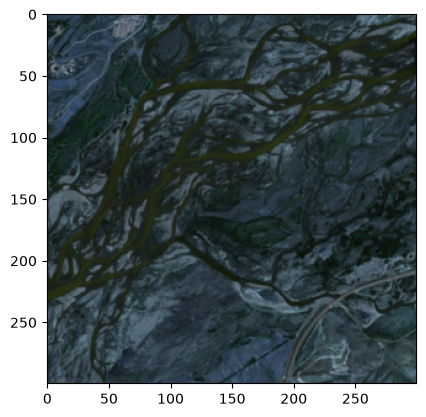

In [6]:
plt.imshow(image[:3].permute(1,2,0))

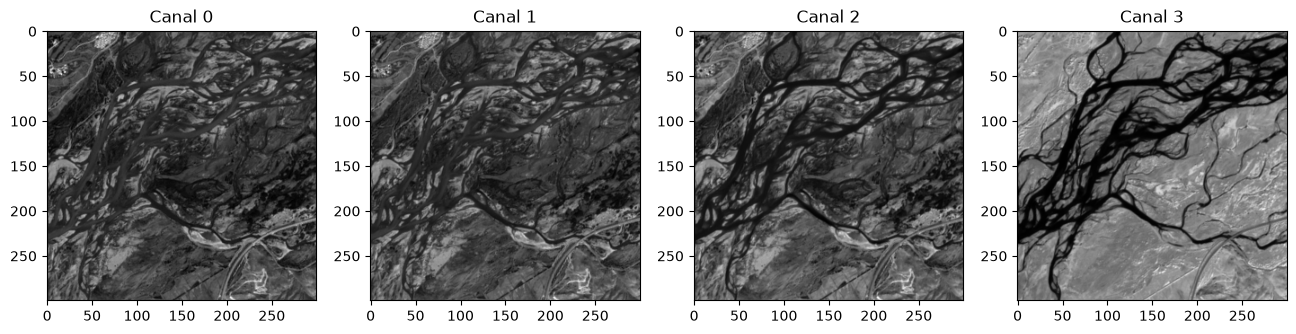

In [7]:
import matplotlib.pyplot as plt

image = x_test[0]  # [4, H, W]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for index, ax in enumerate(axes):
    band = image[index].detach().cpu().numpy()
    ax.imshow(band, cmap="gray")
    ax.set_title(f"Canal {index}")
    

plt.show()


Les éléments du datasets sont des images avec 4 canaux : RGB et proche infrarouge (NIR)

# 2- Generate blurry images

In [8]:
import deepinv as dinv
from deepinv.physics import Denoising, GaussianNoise
from torch.utils.data import DataLoader , TensorDataset


In [9]:
clean_dataset= TensorDataset(torch.stack(x_test))
physics = Denoising(GaussianNoise(sigma=SIGMA)).to(DEVICE)
# deepinv applies the physics to every clean image and saves the (x, y) pairs to HDF5.
data_path = dinv.datasets.generate_dataset(
        train_dataset=clean_dataset,
        test_dataset=None,
        physics=physics,
        device=DEVICE,
        save_dir=MEASUREMENT_DIR,
        num_workers=0,
    )
# train_dataloader = DataLoader(
#         train_dataset, batch_size=BATCH_SIZE, num_workers=num_workers, shuffle=True
#     )


Dataset has been saved at C:\Users\bapti\OneDrive\Documents\CS_3A\projet\PnP-SR-for-multispectral-satellite-imagery\measurements/dinv_dataset0.h5


In [12]:
dataset = dinv.datasets.HDF5Dataset(
    path=data_path,
    train=True,
)

print("Nombre d'images :", len(dataset))

x, y = dataset[0]
print("Image propre :", x.shape)
print("Image bruitée :", y.shape)

Nombre d'images : 1200
Image propre : torch.Size([4, 300, 300])
Image bruitée : torch.Size([4, 300, 300])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.35322008..0.9234835].


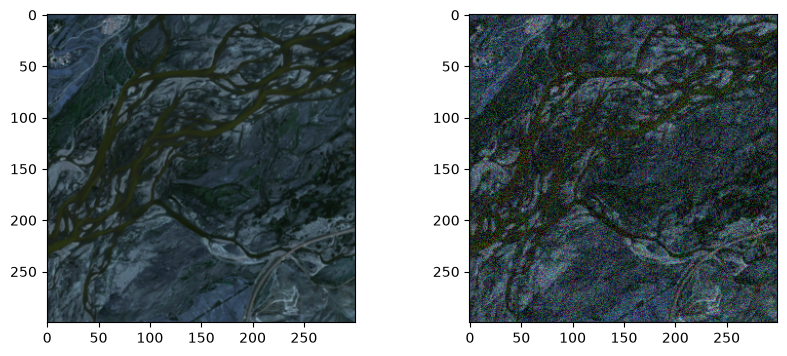

In [19]:
fig , axes = plt.subplots(1,2, figsize=(10,4))

for index, ax in enumerate(axes):
    ax.imshow(dataset[0][index][:3].permute(1,2,0))

# 3- Model loading

In [25]:
import torch.nn as nn

model = dinv.models.DRUNet(pretrained=None, device=DEVICE)

# Architecture adaptée aux 4 bandes spectrales
model.m_head = nn.Conv2d(
    5, 64, kernel_size=3, stride=1, padding=1, bias=False
).to(DEVICE)

model.m_tail = nn.Conv2d(
    64, 4, kernel_size=3, stride=1, padding=1, bias=False
).to(DEVICE)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=True,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

DRUNet(
  (m_head): Conv2d(5, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (m_down1): Sequential(
    (0): ResBlock(
      (res): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
    )
    (1): ResBlock(
      (res): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
    )
    (2): ResBlock(
      (res): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
    )
    (3): ResBlock(
      (res): Sequential(
        (0): Conv2

In [30]:
from tqdm import tqdm

In [34]:
import torch
from torch.utils.data import DataLoader, Subset
import deepinv as dinv

N_IMAGES = 100
eval_subset = Subset(
    dataset,
    range(min(N_IMAGES, len(dataset))),
)

eval_loader = DataLoader(
    eval_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

sigma = torch.tensor(SIGMA, dtype=torch.float32, device=DEVICE)

total_mse = 0.0
total_psnr = 0.0
total_images = 0

with torch.no_grad():
    for clean, noisy in tqdm(eval_loader):
        clean = clean.to(DEVICE)
        noisy = noisy.to(DEVICE)

        denoised = model(noisy, sigma)

        # MSE calculée séparément pour chaque image
        mse = (denoised - clean).square().flatten(1).mean(dim=1)

        # Images propres normalisées dans [0, 1]
        psnr = 10 * torch.log10(
            1.0 / mse.clamp_min(1e-12)
        )

        total_mse += mse.sum().item()
        total_psnr += psnr.sum().item()
        total_images += clean.shape[0]

print(f"Nombre d'images : {total_images}")
print(f"MSE moyenne      : {total_mse / total_images:.6e}")
print(f"PSNR moyen       : {total_psnr / total_images:.2f} dB")

100%|██████████| 13/13 [09:55<00:00, 45.84s/it]

Nombre d'images : 100
MSE moyenne      : 9.009100e-04
PSNR moyen       : 31.01 dB


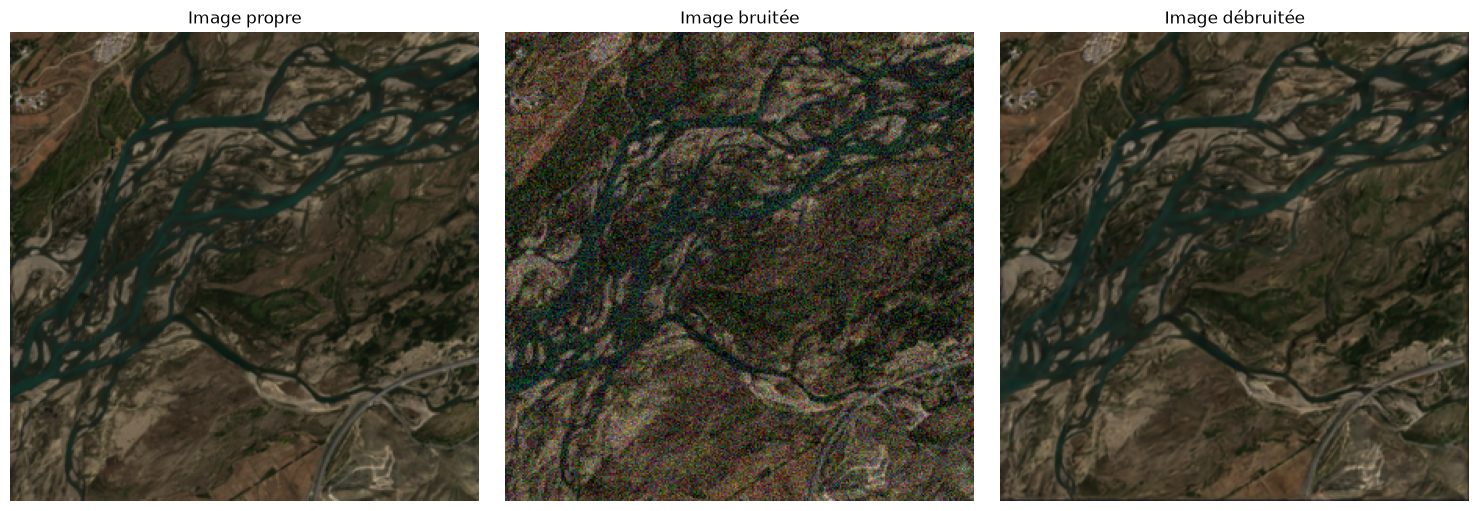

In [33]:
import matplotlib.pyplot as plt

clean, noisy = dataset[0]

with torch.no_grad():
    denoised = model(
        noisy.unsqueeze(0).to(DEVICE),
        sigma,
    ).squeeze(0).cpu()

def to_rgb(image):
    return (
        image[[2, 1, 0]]
        .permute(1, 2, 0)
        .detach()
        .cpu()
        .clamp(0, 1)
        .numpy()
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(to_rgb(clean))
axes[0].set_title("Image propre")

axes[1].imshow(to_rgb(noisy))
axes[1].set_title("Image bruitée")

axes[2].imshow(to_rgb(denoised))
axes[2].set_title("Image débruitée")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

In [37]:
N_IMAGES = 10
norms = []
from norme_spectrale_debruiteur import power_method_q
from deepinv.loss import FNEJacobianSpectralNorm

for index in range(N_IMAGES):
    _, noisy = dataset[index]

    image = noisy.unsqueeze(0).to(DEVICE)
    image = image[:, :, :64, :64]

    norm = power_method_q(
        model=model,
        image=image,
        sigma=sigma,
        n_iter=5,
        epsilon=1e-3,
    )

    value = norm.item()
    norms.append(value)

    print(f"Image (mon implémentation) {index:02d} : {value:.4f}")
    

    deepinv_power_method = FNEJacobianSpectralNorm(
        max_iter=5,
        tol=1e-3,
        eval_mode=False,
        verbose=False,
        reduction="none",
    )

    # Copie indépendante, car DeepInv active requires_grad
    image_deepinv = image.detach().clone()

    # Ne pas utiliser torch.no_grad()
    norm_deepinv = deepinv_power_method(
        image_deepinv,       # point où la Jacobienne est évaluée
        image_deepinv,       # ignoré lorsque interpolation=False
        model,
        sigma,
        interpolation=False,
    )

    print(
        "Norme estimée par DeepInv :",
        norm_deepinv.item(),
    )

print(f"\nNorme moyenne  : {sum(norms) / len(norms):.4f}")
print(f"Norme maximale : {max(norms):.4f}")

Image (mon implémentation) 00 : 11.6071
Norme estimée par DeepInv : 10.79167652130127
Image (mon implémentation) 01 : 5.4840
Norme estimée par DeepInv : 6.011882305145264
Image (mon implémentation) 02 : 9.3736
Norme estimée par DeepInv : 8.80419635772705
Image (mon implémentation) 03 : 7.5718
Norme estimée par DeepInv : 5.883792877197266
Image (mon implémentation) 04 : 10.6096
Norme estimée par DeepInv : 10.625994682312012
Image (mon implémentation) 05 : 5.0393
Norme estimée par DeepInv : 5.696390628814697
Image (mon implémentation) 06 : 6.3315
Norme estimée par DeepInv : 6.455824375152588
Image (mon implémentation) 07 : 4.0399
Norme estimée par DeepInv : 4.274301052093506
Image (mon implémentation) 08 : 4.1945
Norme estimée par DeepInv : 4.585273742675781
Image (mon implémentation) 09 : 7.3134
Norme estimée par DeepInv : 7.201642036437988

Norme moyenne  : 7.1565
Norme maximale : 11.6071
